# 07 - Free mechanical vibrations: the mass-spring-damper system

**MATH 331 - Differential Equations.** Unit U6, Session 13: free undamped and damped motion;
over-, critically and under-damped regimes; amplitude, phase, pseudo-frequency; the RLC circuit
analogy. This notebook applies notebooks 05 (Wronskian, Abel) and 06 (characteristic equation) to the
most important second-order model of engineering. Forced vibrations and resonance come later in the
course (Session 14).

**Sources used to compile this notebook** (full list in Section 10)
* [L] J. Lebl, *Notes on Diffy Qs* (`ode/FullText_Diff_Eq_For_Engineers.pdf`), **Section 2.4,
  Mechanical vibrations**: the model $mx'' + cx' + kx = F(t)$, the RLC circuit and the pendulum,
  Example 2.4.1 (free undamped motion, amplitude and phase), the notation
  $\omega_0 = \sqrt{k/m}$, $p = c/(2m)$, Example 2.4.2 (overdamped release from rest), critical
  damping, underdamping and envelope curves.
* [AD] W.A. Adkins, M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012),
  **Sect. 3.6, Spring Systems**: forces (gravity, Hooke, dashpot), units (Tables 3.1-3.2),
  Examples 1-4, Table 3.4 (spring-body-mass and RCL circuit correspondence).
* Notebooks 05 and 06 of this series.

**What you will learn**
1. How Newton's law, Hooke's law and a linear damper give $mx'' + cx' + kx = 0$, and which
   assumptions this requires.
2. The three regimes (over-, critically, under-damped) as the three cases of the characteristic equation.
3. How the roots move in the complex plane as the damping grows (the **root locus**).
4. Two "global" views: **energy** is dissipated at the rate $cx'^2$, and **phase-plane areas** shrink
   at the rate $c/m$ (Abel's theorem in action).
5. Why engineers design for damping near the critical value.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                     # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. The model

A body of mass $m > 0$ is attached to a spring (stiffness $k > 0$) and to a damper (dashpot) with
coefficient $c \ge 0$. Let $x(t)$ be the displacement from the **rest position** (positive away from the
wall). Three forces act on the body [L, Section 2.4; AD, Sect. 3.6]:

* **spring** (Hooke's law): $-kx$, always pulling back towards the rest position;
* **damper**: $-cx'$, proportional to the velocity and opposed to it (a *linear* damping model);
* **external force** $F(t)$ (zero in this notebook: *free* motion).

Newton's second law $m x'' = \sum F$ gives

$$
\boxed{\;m\,x'' + c\,x' + k\,x = F(t)\;}
$$

*Vertical spring.* Gravity adds a constant force $mg$. Measuring $x$ from the **static equilibrium**
(where $k\,\Delta\ell = mg$, $\Delta\ell$ = static stretch) the constant cancels and the same equation
holds [AD, Sect. 3.6]. This is how $k$ is often measured: $k = mg/\Delta\ell$.

**Units (SI).** $m$ [kg], $k$ [N/m], $c$ [N s/m]. Lebl's convention: undamped if $c = 0$, damped if $c > 0$;
free if $F \equiv 0$, forced otherwise.

**The same equation elsewhere** [L, Section 2.4; AD, Table 3.4]. In a series RLC circuit, the charge $Q$ on
the capacitor satisfies $LQ'' + RQ' + Q/C = E(t)$:

| mechanical | electrical |
|---|---|
| displacement $x$ | charge $Q$ |
| velocity $x'$ | current $I = Q'$ |
| mass $m$ | inductance $L$ |
| damping $c$ | resistance $R$ |
| stiffness $k$ | inverse capacitance $1/C$ |
| force $F(t)$ | source voltage $E(t)$ |

A pendulum of length $L$ obeys $\theta'' + (g/L)\sin\theta = 0$, which for small swings
($\sin\theta \approx \theta$) is the same equation with $c = 0$, $k/m = g/L$.

**Worked models from [AD, Sect. 3.6]** (data converted to SI as in the book):
* Example 2: spring stretched 0.2 m by 5 N $\Rightarrow k = 25$ N/m; damper 5 N at 0.5 m/s
  $\Rightarrow c = 10$ N s/m; $m = 4$ kg; pulled down 0.5 m and released downward at 1 m/s:
  $4x'' + 10x' + 25x = 0$, $x(0) = 0.5$, $x'(0) = 1$.
* Example 3 (English units): a 4 lb body stretches a spring 3 in $\Rightarrow k = 16$ lb/ft,
  $m = 4/32 = 1/8$ slug, $c = 8/2 = 4$ lb s/ft: $\tfrac18x'' + 4x' + 16x = 0$, $x(0) = 1$, $x'(0) = 0$.

In [2]:
# Classify the two models of Adkins-Davidson Sect. 3.6 (Examples 2 and 3) with the tested helpers
for name, (m, c, k) in {"AD Example 2": (4, 10, 25), "AD Example 3": (1 / 8, 4, 16)}.items():
    r1, r2 = ol.characteristic_roots(m, c, k)
    print(f"{name}: m={m}, c={c}, k={k};  c^2 - 4mk = {c**2 - 4 * m * k:+.1f}  ->  "
          f"{ol.damping_regime(m, c, k)};  roots {r1:.3f}, {r2:.3f}")

AD Example 2: m=4, c=10, k=25;  c^2 - 4mk = -300.0  ->  underdamped;  roots -1.250+2.165j, -1.250-2.165j
AD Example 3: m=0.125, c=4, k=16;  c^2 - 4mk = +8.0  ->  overdamped;  roots -4.686+0.000j, -27.314+0.000j


## 2. Standard form and the three regimes

Divide by $m$ and introduce [L, Section 2.4]

$$
\omega_0 = \sqrt{\frac km}\ \ \text{(natural angular frequency)},\qquad
p = \frac{c}{2m},\qquad \zeta = \frac{p}{\omega_0} = \frac{c}{2\sqrt{mk}}\ \ \text{(damping ratio)}:
\qquad x'' + 2p\,x' + \omega_0^2\,x = 0 .
$$

The characteristic equation $r^2 + 2pr + \omega_0^2 = 0$ (notebook 06) has roots
$r_{1,2} = -p \pm \sqrt{p^2 - \omega_0^2}$, and $p^2 - \omega_0^2$ has the sign of $c^2 - 4mk$.
The **critical damping** is $c_{\mathrm{crit}} = 2\sqrt{mk}$ ($\zeta = 1$).

| regime | condition | roots | solution |
|---|---|---|---|
| undamped | $c = 0$ | $\pm i\omega_0$ | $A\cos\omega_0t + B\sin\omega_0t$ |
| underdamped | $0 < c < c_{\mathrm{crit}}$ | $-p \pm i\omega_1$, $\ \omega_1 = \sqrt{\omega_0^2 - p^2}$ | $e^{-pt}(A\cos\omega_1t + B\sin\omega_1t)$ |
| critically damped | $c = c_{\mathrm{crit}}$ | $-p$ (double) | $(C_1 + C_2t)\,e^{-pt}$ |
| overdamped | $c > c_{\mathrm{crit}}$ | $-p \pm \sqrt{p^2 - \omega_0^2}$, both $< 0$ | $C_1e^{r_1t} + C_2e^{r_2t}$ |

With $x(0) = x_0$, $x'(0) = v_0$ the constants are (used in `ol.free_response`)

* underdamped: $A = x_0$, $B = (v_0 + px_0)/\omega_1$;
* critical: $C_1 = x_0$, $C_2 = v_0 + px_0$;
* overdamped: $C_1 = (v_0 - r_2x_0)/(r_1 - r_2)$, $C_2 = x_0 - C_1$.

For $c > 0$ **every** solution tends to $0$: both roots have negative real part (notebook 06, Section 7).

In [3]:
# SymPy derives the underdamped constants from the initial conditions
t = sp.symbols("t", real=True)
p_, w1, x0_, v0_, A, B = sp.symbols("p omega_1 x_0 v_0 A B", real=True)
x_ud = sp.exp(-p_ * t) * (A * sp.cos(w1 * t) + B * sp.sin(w1 * t))
consts = sp.solve([x_ud.subs(t, 0) - x0_, sp.diff(x_ud, t).subs(t, 0) - v0_], [A, B])
display(Math(r"A = " + sp.latex(consts[A]) + r",\qquad B = " + sp.latex(consts[B])))

# ...and checks the helper against the ODE in all regimes (m = 1, k = 4, so c_crit = 4)
for c in (0.0, 1.0, 4.0, 10.0):
    ts = np.linspace(0, 6, 6001)
    x = ol.free_response(ts, 1.0, c, 4.0, 1.0, -2.0)
    dx, ddx = np.gradient(x, ts), np.gradient(np.gradient(x, ts), ts)
    res = np.max(np.abs(ddx + c * dx + 4 * x)[5:-5])       # finite-difference residual of the ODE
    print(f"c = {c:4.1f}  {ol.damping_regime(1, c, 4):18s} max |x'' + c x' + 4x| ~ {res:.1e}")

<IPython.core.display.Math object>

c =  0.0  undamped           max |x'' + c x' + 4x| ~ 7.5e-06
c =  1.0  underdamped        max |x'' + c x' + 4x| ~ 4.3e-06
c =  4.0  critically damped  max |x'' + c x' + 4x| ~ 9.4e-11
c = 10.0  overdamped         max |x'' + c x' + 4x| ~ 2.2e-04


## 3. Free undamped motion: amplitude and phase

With $c = 0$: $x = A\cos\omega_0t + B\sin\omega_0t = R\cos(\omega_0t - \gamma)$ with $A = x_0$,
$B = v_0/\omega_0$, **amplitude** $R = \sqrt{A^2 + B^2}$ and **phase shift** $\gamma$ given by
$\tan\gamma = B/A$ in the correct quadrant: in code, `gamma = np.arctan2(B, A)` [L, Section 2.4, Note].
Period $T = 2\pi/\omega_0$, frequency $\omega_0/(2\pi)$ Hz: **independent of the amplitude** (unlike a
real pendulum).

**[L, Example 2.4.1]** $m = 2$ kg, $k = 8$ N/m; the mass is $0.5$ m from rest, moving at $1$ m/s:
$2x'' + 8x = 0$, $x(0) = 0.5$, $x'(0) = 1$. Then $\omega_0 = 2$, frequency $1/\pi \approx 0.318$ Hz,
$A = B = 0.5$, $R = \sqrt{0.5} \approx 0.707$ m, $\gamma = \pi/4 \approx 0.785$.

omega0 = 2.0, frequency = 0.318 Hz, A = 0.5, B = 0.5, R = 0.7071 (sqrt(0.5) = 0.7071), gamma = 0.785 rad


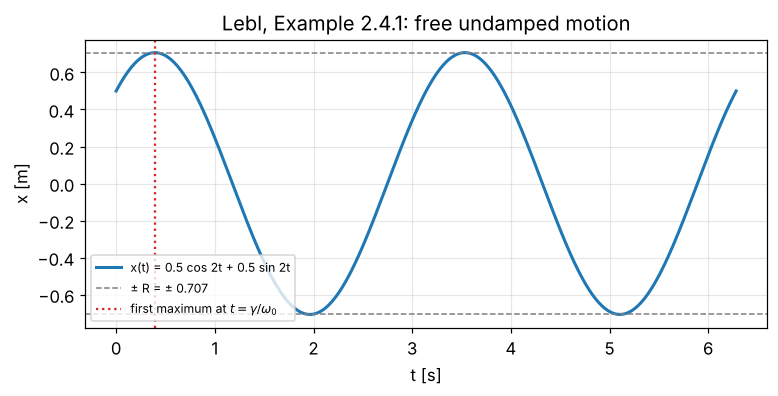

In [4]:
m, c, k, x0, v0 = 2.0, 0.0, 8.0, 0.5, 1.0               # Lebl, Example 2.4.1
w0 = np.sqrt(k / m)
A, B = x0, v0 / w0
R, gamma = np.hypot(A, B), np.arctan2(B, A)             # arctan2 picks the right quadrant
print(f"omega0 = {w0}, frequency = {w0 / (2 * np.pi):.3f} Hz, A = {A}, B = {B}, "
      f"R = {R:.4f} (sqrt(0.5) = {np.sqrt(0.5):.4f}), gamma = {gamma:.3f} rad")

ts = np.linspace(0, 2 * np.pi, 600)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ts, ol.free_response(ts, m, c, k, x0, v0), lw=2, label="x(t) = 0.5 cos 2t + 0.5 sin 2t")
ax.axhline(R, color="gray", ls="--", lw=1)
ax.axhline(-R, color="gray", ls="--", lw=1, label=f"± R = ± {R:.3f}")
ax.axvline(gamma / w0, color="tab:red", ls=":", label=r"first maximum at $t = \gamma/\omega_0$")
ax.set(xlabel="t [s]", ylabel="x [m]", title="Lebl, Example 2.4.1: free undamped motion")
ax.legend(loc="lower left", fontsize=8)
plt.show()

## 4. Free damped motion: the three regimes side by side

Same mass and spring ($m = 1$, $k = 4$, so $\omega_0 = 2$ and $c_{\mathrm{crit}} = 4$), same initial condition
(released from rest at $x_0 = 1$), three values of $c$. Notice [L, Section 2.4]:

* **underdamped**: oscillation with **pseudo-frequency** $\omega_1 < \omega_0$ inside the **envelope**
  $\pm R\,e^{-pt}$; the zero crossings are equally spaced, $\pi/\omega_1$ apart;
* **critically damped** and **overdamped**: no oscillation; the graph crosses zero **at most once**
  (notebook 06, Section 3);
* overdamped is *slower* than critical: heavy damping makes the mass "crawl" back.

**[L, Example 2.4.2]** For release from rest ($v_0 = 0$) in the overdamped case,
$x(t) = \dfrac{x_0}{r_1 - r_2}\left(r_1e^{r_2t} - r_2e^{r_1t}\right)$; the code checks it.

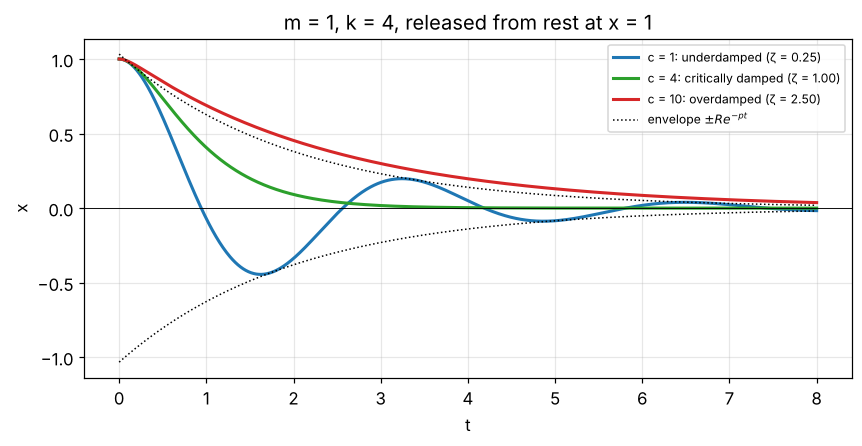

Lebl Example 2.4.2 vs odelib, max difference: 3.3306690738754696e-16


In [5]:
m, k, x0, v0 = 1.0, 4.0, 1.0, 0.0
ts = np.linspace(0, 8, 800)
fig, ax = plt.subplots(figsize=(9, 4))
for c, col in ((1.0, "tab:blue"), (4.0, "tab:green"), (10.0, "tab:red")):
    x = ol.free_response(ts, m, c, k, x0, v0)
    zeta = c / (2 * np.sqrt(m * k))
    ax.plot(ts, x, color=col, lw=2, label=f"c = {c:g}: {ol.damping_regime(m, c, k)} (ζ = {zeta:.2f})")
# envelope of the underdamped curve: R e^{-pt}, with R = sqrt(A^2 + B^2), A = x0, B = (v0 + p x0)/w1
p, w1 = 0.5, np.sqrt(4 - 0.25)
R = np.hypot(x0, (v0 + p * x0) / w1)
ax.plot(ts, R * np.exp(-p * ts), "k:", lw=1, label=r"envelope $\pm R e^{-pt}$")
ax.plot(ts, -R * np.exp(-p * ts), "k:", lw=1)
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="t", ylabel="x", title="m = 1, k = 4, released from rest at x = 1")
ax.legend(fontsize=8)
plt.show()

# Lebl, Example 2.4.2 (overdamped release from rest) against the general helper
r1, r2 = (-5 + np.sqrt(21)), (-5 - np.sqrt(21))              # c = 10: p = 5, roots -5 +- sqrt(25 - 4)
lebl = x0 / (r1 - r2) * (r1 * np.exp(r2 * ts) - r2 * np.exp(r1 * ts))
print("Lebl Example 2.4.2 vs odelib, max difference:",
      np.max(np.abs(lebl - ol.free_response(ts, m, 10.0, k, x0, 0.0))))

## 5. The root locus: how the roots move as $c$ grows

Fix $m$ and $k$ and increase $c$ from $0$:

* $c = 0$: roots $\pm i\omega_0$ on the imaginary axis;
* $0 < c < c_{\mathrm{crit}}$: $r = -p \pm i\omega_1$ with $|r|^2 = p^2 + \omega_1^2 = \omega_0^2$: the roots
  travel on the **circle of radius $\omega_0$** (indeed $r_1r_2 = \omega_0^2$, Vieta);
* $c = c_{\mathrm{crit}}$: they collide on the real axis at $-\omega_0$;
* $c > c_{\mathrm{crit}}$: they split along the real axis, one towards $-\infty$, the other towards
  $0^-$ (since $r_1r_2 = \omega_0^2$ stays fixed).

The slowest-decaying part of the solution behaves like $e^{(\max \operatorname{Re} r)\,t}$. The
**decay rate** $\sigma = -\max\operatorname{Re} r$ is therefore

$$
\sigma(\zeta) = \begin{cases} \zeta\,\omega_0, & \zeta \le 1,\\ \omega_0\big(\zeta - \sqrt{\zeta^2 - 1}\big), & \zeta \ge 1,\end{cases}
$$

which is **largest at $\zeta = 1$**. Critical damping gives the fastest return without oscillation.
This is why car suspensions, door closers and measuring instruments are designed with $\zeta$ close
to (usually a little below) 1.

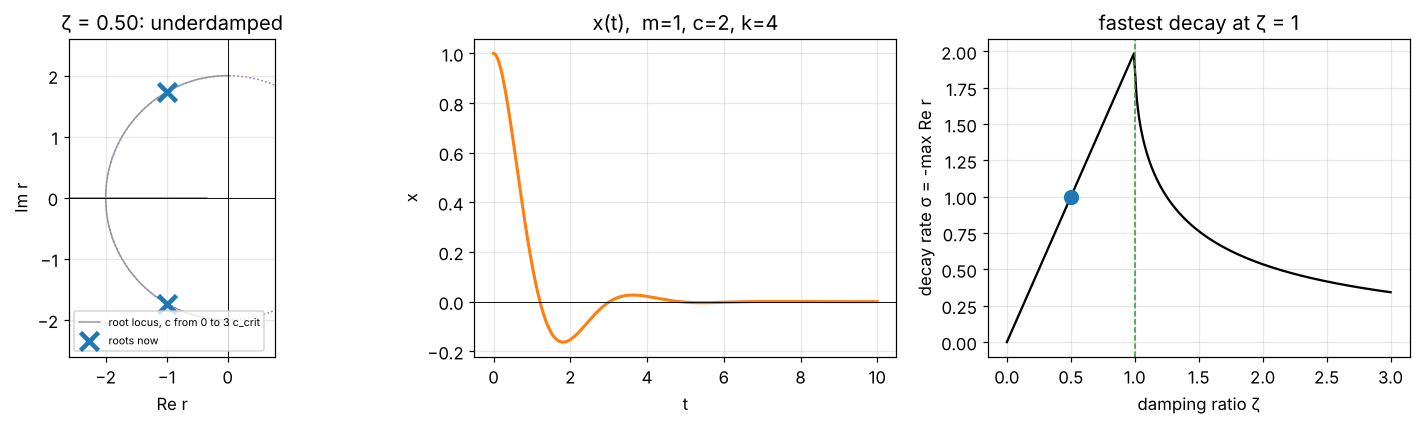

In [6]:
def plot_root_locus(c=2.0, m=1.0, k=4.0, x0=1.0, v0=0.0):
    w0, c_crit = np.sqrt(k / m), 2 * np.sqrt(m * k)
    fig, axs = plt.subplots(1, 3, figsize=(13.5, 4))
    # (1) root locus for c in [0, 3 c_crit], current roots marked
    ax = axs[0]
    cs = np.linspace(0, 3 * c_crit, 400)
    roots = np.array([ol.characteristic_roots(m, cc, k) for cc in cs])
    ax.plot(roots[:, 0].real, roots[:, 0].imag, color="0.6", lw=1)
    ax.plot(roots[:, 1].real, roots[:, 1].imag, color="0.6", lw=1, label="root locus, c from 0 to 3 c_crit")
    r1, r2 = ol.characteristic_roots(m, c, k)
    ax.plot([r1.real, r2.real], [r1.imag, r2.imag], "x", ms=12, mew=3, color="tab:blue", label="roots now")
    ax.add_patch(plt.Circle((0, 0), w0, fill=False, ls=":", color="tab:purple"))
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    lim = 1.3 * max(w0, abs(r2.real))
    ax.set(xlim=(-lim, 0.3 * lim), ylim=(-1.3 * w0, 1.3 * w0), aspect="equal", xlabel="Re r", ylabel="Im r",
           title=f"ζ = {c / c_crit:.2f}: {ol.damping_regime(m, c, k)}")
    ax.legend(fontsize=7, loc="lower left")
    # (2) the motion
    ax = axs[1]
    ts = np.linspace(0, 10, 800)
    ax.plot(ts, ol.free_response(ts, m, c, k, x0, v0), lw=2, color="tab:orange")
    ax.axhline(0, color="k", lw=0.6)
    ax.set(xlabel="t", ylabel="x", title=f"x(t),  m={m:g}, c={c:g}, k={k:g}")
    # (3) decay rate versus damping ratio
    ax = axs[2]
    zs = np.linspace(0, 3, 300)
    sigma = np.where(zs <= 1, zs * w0, w0 * (zs - np.sqrt(np.maximum(zs**2 - 1, 0))))
    ax.plot(zs, sigma, color="k")
    ax.plot(c / c_crit, -max(r1.real, r2.real), "o", ms=9, color="tab:blue")
    ax.axvline(1, color="tab:green", ls="--", lw=1)
    ax.set(xlabel="damping ratio ζ", ylabel="decay rate σ = -max Re r", title="fastest decay at ζ = 1")
    plt.tight_layout()
    plt.show()


plot_root_locus(2.0)

In [7]:
interact(plot_root_locus,
         c=FloatSlider(value=2.0, min=0.0, max=12.0, step=0.1, description="c", continuous_update=False),
         m=FloatSlider(value=1.0, min=0.25, max=4.0, step=0.25, description="m", continuous_update=False),
         k=FloatSlider(value=4.0, min=0.5, max=16.0, step=0.5, description="k", continuous_update=False),
         x0=FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.1, description="x(0)", continuous_update=False),
         v0=FloatSlider(value=0.0, min=-5.0, max=5.0, step=0.1, description="x'(0)",
                        continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='c', max=12.0), FloatSlider(…

## 6. Energy: where does the motion go?

The mechanical energy is kinetic plus elastic potential energy:

$$
E(t) = \tfrac12\,m\,x'^2 + \tfrac12\,k\,x^2 .
$$

Differentiate and use the equation $mx'' = -cx' - kx$:

$$
\frac{dE}{dt} = m\,x'x'' + k\,x\,x' = x'\,(mx'' + kx) = -\,c\,x'^2 \;\le\; 0 .
$$

* $c = 0$: $E$ is **conserved**; the phase-plane trajectory is the ellipse $\tfrac12mx'^2 + \tfrac12kx^2 = E$.
* $c > 0$: the damper converts mechanical energy into heat at the rate $c\,x'^2$. $E$ decreases,
  momentarily stalling when $x' = 0$ (turning points). That is why the decay looks like a
  staircase.

The same computation for the RLC circuit: $\tfrac12LI^2 + \tfrac{Q^2}{2C}$ (magnetic + electric energy)
decreases at the rate $RI^2$ (Joule heating).

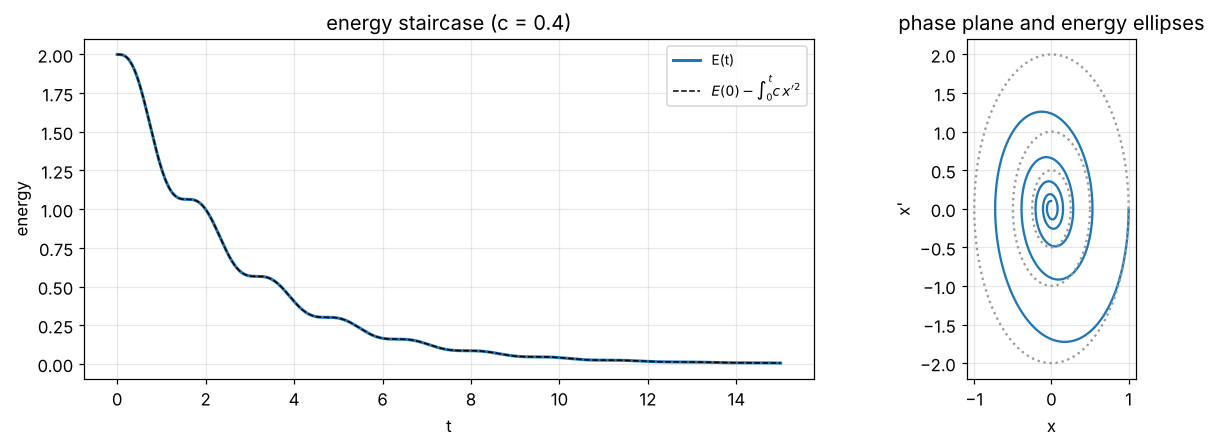

max |E - (E(0) - dissipated)| = 0.00011840706081756025


In [8]:
m, c, k, x0, v0 = 1.0, 0.4, 4.0, 1.0, 0.0
ts = np.linspace(0, 15, 3001)
x = ol.free_response(ts, m, c, k, x0, v0)
v = np.gradient(x, ts)                                   # velocity by finite differences (fine here)
E = 0.5 * m * v**2 + 0.5 * k * x**2

# Energy balance: E(t) = E(0) - integral_0^t c v^2 ds  (cumulative trapezoidal rule)
dissipated = np.concatenate([[0], np.cumsum(0.5 * (c * v[1:]**2 + c * v[:-1]**2) * np.diff(ts))])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.plot(ts, E, lw=2, label="E(t)")
ax1.plot(ts, E[0] - dissipated, "k--", lw=1, label=r"$E(0) - \int_0^t c\,x'^2$")
ax1.set(xlabel="t", ylabel="energy", title=f"energy staircase (c = {c})")
ax1.legend()
ax2.plot(x, v, lw=1.5)
for EE in (E[0], E[0] / 4, E[0] / 16):                    # level sets of E (undamped ellipses)
    th = np.linspace(0, 2 * np.pi, 200)
    ax2.plot(np.sqrt(2 * EE / k) * np.cos(th), np.sqrt(2 * EE / m) * np.sin(th), ":", color="0.6")
ax2.set(xlabel="x", ylabel="x'", aspect="equal", title="phase plane and energy ellipses")
plt.tight_layout()
plt.show()
print("max |E - (E(0) - dissipated)| =", np.max(np.abs(E - (E[0] - dissipated))))

## 7. Phase-plane areas shrink: Abel's theorem as a physical law

Notebook 05, Section 3.1: the Wronskian of two solutions is the signed **area** of the parallelogram
spanned by their states $(x, x')$. For $x'' + \frac cm x' + \frac km x = 0$, Abel's theorem
($p = c/m$) gives

$$
W(t) = W(0)\,e^{-(c/m)\,t}.
$$

Since the equation is linear, the flow maps **any** region of initial states to a region whose area
changes by the same factor (a square is mapped to a parallelogram, so the statement extends to any
shape that can be filled with small squares). Below, a square "cloud" of 400 initial states
is followed in time:

* with $c = 0$ the cloud rotates and shears, but its area is **conserved** (Liouville's theorem of
  Hamiltonian mechanics in its simplest form);
* with $c > 0$ it shrinks onto the origin, its area decaying **exactly** as $e^{-(c/m)t}$, whatever
  $k$ is: the area does not care whether the motion oscillates.

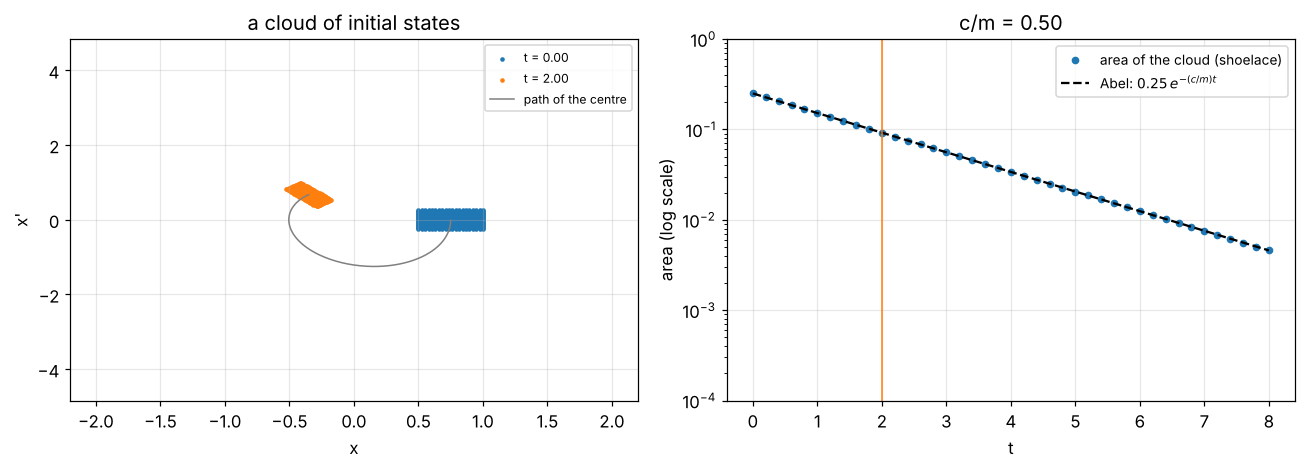

In [9]:
def plot_cloud(c=0.5, m=1.0, k=4.0, t_now=2.0):
    # 20 x 20 grid of initial states in the square [0.5, 1.0] x [-0.25, 0.25] (area 0.25)
    g = np.linspace(0, 1, 20)
    X0, V0 = np.meshgrid(0.5 + 0.5 * g, -0.25 + 0.5 * g)
    X0, V0 = X0.ravel(), V0.ravel()

    def state(t):
        """Exact states (x, x') at time t of all the initial states (vectorised over the cloud)."""
        h = 1e-6
        x = np.array([ol.free_response(t, m, c, k, a, b) for a, b in zip(X0, V0, strict=True)])
        xh = np.array([ol.free_response(t + h, m, c, k, a, b) for a, b in zip(X0, V0, strict=True)])
        return x, (xh - x) / h

    corners = [(0.5, -0.25), (1.0, -0.25), (1.0, 0.25), (0.5, 0.25)]   # corners of the initial square

    def area_at(t):
        """Shoelace formula for the area of the image of the square (it is a parallelogram)."""
        pts = []
        for a, b in corners:
            xx = ol.free_response(t, m, c, k, a, b)
            vv = (ol.free_response(t + 1e-6, m, c, k, a, b) - xx) / 1e-6
            pts.append((xx, vv))
        P = np.array(pts)
        return 0.5 * abs(np.dot(P[:, 0], np.roll(P[:, 1], -1)) - np.dot(P[:, 1], np.roll(P[:, 0], -1)))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
    for tt, col in ((0.0, "tab:blue"), (t_now, "tab:orange")):
        xs, vs = state(tt)
        ax1.scatter(xs, vs, s=4, color=col, label=f"t = {tt:.2f}")
    ts = np.linspace(0, t_now, 200)
    centre = ol.free_response(ts, m, c, k, 0.75, 0.0)               # path of the centre of the square
    ax1.plot(centre, np.gradient(centre, ts), color="0.5", lw=1, label="path of the centre")
    lim = 1.1 * max(1.0, np.sqrt(k / m))
    ax1.set(xlim=(-lim, lim), ylim=(-2.2 * lim, 2.2 * lim), xlabel="x", ylabel="x'",
            title="a cloud of initial states")
    ax1.legend(loc="upper right", fontsize=8)

    tg = np.linspace(0, 8, 41)
    ax2.semilogy(tg, [area_at(tt) for tt in tg], "o", ms=4, label="area of the cloud (shoelace)")
    ax2.semilogy(tg, 0.25 * np.exp(-(c / m) * tg), "k--", label=r"Abel: $0.25\,e^{-(c/m)t}$")
    ax2.axvline(t_now, color="tab:orange", lw=1)
    ax2.set(xlabel="t", ylabel="area (log scale)", ylim=(1e-4, 1), title=f"c/m = {c / m:.2f}")
    ax2.legend()
    plt.tight_layout()
    plt.show()


plot_cloud(0.5, t_now=2.0)

In [10]:
interact(plot_cloud,
         c=FloatSlider(value=0.5, min=0.0, max=2.0, step=0.1, description="c", continuous_update=False),
         m=FloatSlider(value=1.0, min=0.5, max=3.0, step=0.25, description="m", continuous_update=False),
         k=FloatSlider(value=4.0, min=1.0, max=10.0, step=0.5, description="k", continuous_update=False),
         t_now=FloatSlider(value=2.0, min=0.0, max=8.0, step=0.25, description="t", continuous_update=False));

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='c', max=2.0), FloatSlider(v…

Try $c = 0$: the orange cloud is a rotated and sheared copy of the blue square, and the area points
stay on a horizontal line. Then increase $k$ at fixed $c$: the motion changes, the area law does not.

## 8. An RLC circuit, solved two ways

A series circuit with $L = 0.5$ H, $R = 2\ \Omega$, $C = 0.08$ F and no source; the capacitor starts with
$Q(0) = 1$ C, and $I(0) = 0$. By the analogy table, $m \to L$, $c \to R$, $k \to 1/C = 12.5$:
$c_{\mathrm{crit}} = 2\sqrt{L/C} = 5\ \Omega > R$, so the circuit is **underdamped** and the charge oscillates
while decaying. We compare the exact formula with a numerical solution (`solve_ivp`, notebook 04).

regime: underdamped | R_crit = 2 sqrt(L/C) = 5.0 ohm


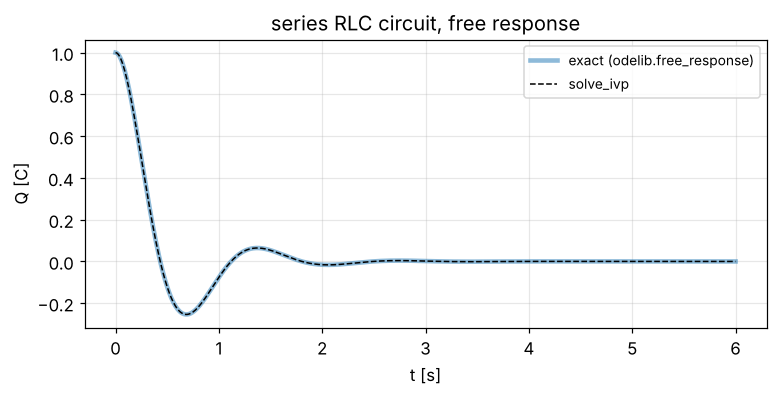

max |exact - numerical| = 1.8322288131145115e-11


In [11]:
Lh, Rr, Cf = 0.5, 2.0, 0.08                              # henry, ohm, farad
print("regime:", ol.damping_regime(Lh, Rr, 1 / Cf), "| R_crit = 2 sqrt(L/C) =", 2 * np.sqrt(Lh / Cf), "ohm")

ts = np.linspace(0, 6, 601)
Q_exact = ol.free_response(ts, Lh, Rr, 1 / Cf, 1.0, 0.0)
# numerical: first-order system (Q, I)' = (I, -(R I + Q/C)/L)
sol = solve_ivp(lambda t, u: [u[1], -(Rr * u[1] + u[0] / Cf) / Lh], (0, 6), [1.0, 0.0],
                t_eval=ts, rtol=1e-10, atol=1e-12)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(ts, Q_exact, lw=3, alpha=0.5, label="exact (odelib.free_response)")
ax.plot(ts, sol.y[0], "k--", lw=1, label="solve_ivp")
ax.set(xlabel="t [s]", ylabel="Q [C]", title="series RLC circuit, free response")
ax.legend()
plt.show()
print("max |exact - numerical| =", np.max(np.abs(Q_exact - sol.y[0])))

## 9. Summary and exercises

* Model: $mx'' + cx' + kx = 0$; $\omega_0 = \sqrt{k/m}$, $p = c/(2m)$, $\zeta = c/(2\sqrt{mk})$.
* $\zeta = 0$: harmonic motion, energy conserved; $0 < \zeta < 1$: decaying oscillation, pseudo-frequency
  $\omega_1 = \omega_0\sqrt{1 - \zeta^2}$, envelope $Re^{-pt}$; $\zeta = 1$: fastest non-oscillatory return;
  $\zeta > 1$: slow, non-oscillatory return.
* Energy decreases at the rate $cx'^2$. Phase-plane areas decrease as $e^{-(c/m)t}$ (Abel).
* RLC circuits obey the same equation ($L, R, 1/C$ in place of $m, c, k$).

### Exercises

1. *(AD 3.6, Example 2)* Solve $4x'' + 10x' + 25x = 0$, $x(0) = 0.5$, $x'(0) = 1$. Write the answer
   as $Re^{-pt}\cos(\omega_1t - \gamma)$ and give $R$, $\gamma$, the pseudo-period and the envelope.
2. *(AD 3.6, Example 3)* Solve $\tfrac18x'' + 4x' + 16x = 0$, $x(0) = 1$, $x'(0) = 0$. Does the body
   ever pass through equilibrium? Justify with the "at most one crossing" argument.
3. *(L, Example 2.4.1, continued)* Add a damper with $c = 1$ N s/m. How long until the envelope
   is below 1 % of its initial value?
4. Show that in the underdamped case the time between successive maxima is $2\pi/\omega_1$ and that the
   ratio of successive maxima is $e^{-2\pi p/\omega_1}$. Its logarithm, the *logarithmic decrement*, is
   used to **measure** $\zeta$ experimentally. Express $\zeta$ in terms of it.
5. Prove the decay-rate formula of Section 5 and that it is maximal at $\zeta = 1$.
6. Using Section 7, explain why no choice of $c > 0$ can make the cloud of states keep its area,
   and why no choice of $k$ can change the area law.
7. For which $R$ is the RLC circuit of Section 8 critically damped? Check with the slider of Section 5
   (using the analogy).

## 10. References

* **[L]** J. Lebl, *Notes on Diffy Qs: Differential Equations for Engineers*,
  `ode/FullText_Diff_Eq_For_Engineers.pdf`, Section 2.4 *Mechanical vibrations*. (Course textbook.)
* **[AD]** W.A. Adkins, M.G. Davidson, *Ordinary Differential Equations*, Springer UTM (2012),
  Section 3.6 *Spring Systems* (Examples 1-4, Tables 3.1, 3.2, 3.4).
* Notebook 05 (Wronskian, Abel's theorem, phase-plane area) and notebook 06 (characteristic equation).